<a href="https://colab.research.google.com/github/Xyrfo/Pembelajaran-Mesin/blob/main/JS07/lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS07 - Lab 1
## Klasterisasi dengan K-Means (Dataset Iris)

Pada modul praktikum ini, kita akan langsung mempraktikkan pembuatan model K-Means dengan menggunakan python. Kita akan menggunakan contoh kasus yang sederhana, yaitu dengan menggunakan dataset iris.

Iris merupakan dataset yang menggambarkan 4 jenis bunga Iris berdasarkan panjang dan lebar dari sepal dan petal bunga. **Dataset ini sebetulnya telah memiliki label** (sehingga dapat digunakan untuk proses klasifikasi). Pada praktikum ini, kita akan berasumsi bahwa dataset tidak memiliki label sehingga relevan untuk proses klasterisasi.

## Langkah 0 - Download Dataset

Dataset yang dipakai adalah `iris.csv` yang tersedia pada folder kerja. Berbeda dengan `Iris.csv` pada modul, file ini memakai header gaya scikit-learn (`sepal length (cm)`, `sepal width (cm)`, `petal length (cm)`, `petal width (cm)`, `species`).

Jika menjalankan di Google Colab, unggah `iris.csv` terlebih dahulu.

In [6]:
try:
    from google.colab import files
    files.upload()
except ImportError:
    pass

Saving iris.csv to iris (1).csv


## Langkah 1 - Import Library

Import library yang dibutuhkan

In [7]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

## Langkah 2 - Load dan Inspeksi Data

Pada tahap ini, kita akan memuat data ke dalam dataframe kemudian melakukan inspeksi data untuk 5 data pertama.

In [8]:
df = pd.read_csv('iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Selanjutnya, lakukan inspeksi profile data

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


## Langkah 3 - Seleksi Fitur

Dikarenakan kita hanya membutuhkan fitur untuk proses klasterisasi, maka kita perlu memisahkan antara fitur dan label dengan menggunakan proses *slicing* data.

Pada modul, `X = df.iloc[:, 1:-1]` karena kolom pertama adalah `Id`. Pada `iris.csv` lokal tidak ada kolom `Id`, sehingga seluruh kolom numerik dipakai sebagai fitur dan kolom `species` dibuang.

In [10]:
# Features Selection
X = df.select_dtypes(include=np.number) # slice the features
y = df.iloc[:, -1] # this is the labels (we don't need it)

Cek data fitur dengan cara,

In [11]:
print(X.head())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0   1            5.1           3.5            1.4           0.2
1   2            4.9           3.0            1.4           0.2
2   3            4.7           3.2            1.3           0.2
3   4            4.6           3.1            1.5           0.2
4   5            5.0           3.6            1.4           0.2


## Langkah 4 - Plotting

Pada tahap ini, kita akan melakukan proses plot menggunakan scatter plot untuk melihat sebaran data berdasarkan 2 fitur, yaitu `SepalLengthCm` dan `SepalWidthCm`. Pada dataset lokal, kolom tersebut bernama `sepal length (cm)` dan `sepal width (cm)`.

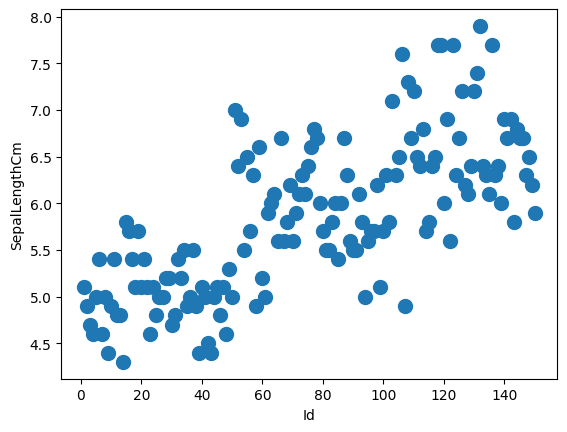

In [12]:
# Make a scatterplot using
# SepalLengthCm and SepalWidthCm
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

Jika diperhatikan secara visual, kita mungkin dapat berasumsi bahwa terdapat dua *cluster* pada data.

## Langkah 5 - Membuat Model K-Means

Selanjutnya, kita akan membuat model K-Means dengan asumsi terdapat dua *cluster* sesuai dengan amatan visual pada scatterplot.

In [13]:
# Build a K-Means Model
# Based on visual inspection using scatterplot,
# we can assumpt that the data has 2 cluster
# (even though, from the label, there are 3 labels in this data)

from sklearn.cluster import KMeans

# Initiate K-Means object with numbur of cluster is 2
cl_kmeans = KMeans(n_clusters=2, random_state=42)

# Fit and predict
y_kmeans = cl_kmeans.fit_predict(X)

Setelah model mempelajari data yang kita miliki melalui fungsi `fit_predict()`, kita dapat melakukan pengecekan hasil klasterisasi dengan memanfaatkan scatterplot.

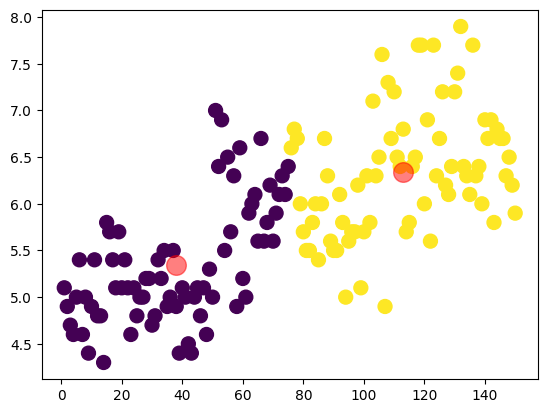

In [14]:
# Plot the clustering result
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

# Plot the centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

## Langkah 6 - Evaluasi Model

Untuk mengetahui apakah model klasterisasi yang dihasilkan memiliki performa yang baik, maka kita akan melakukan proses evaluasi. Nilai metrik evaluasi yang dapat kita gunakan salah satunya adalah ***sum of square error* (SSE)**. Untuk mendapatkan nilai SSE, kita cukup mengakses properti `inertia_` dari objek K-Means yang telah dilatih sebelumnya.

In [15]:
# Print SSE value
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 70616.29893333331


NB: Anda mungkin mendapatkan nilai yang berbeda. ***Ingat, titik centroid awal ditentukan pada lokasi yang acak!***

## Langkah 7 - Menentukan $k$ terbaik dengan Elbow Method

Pada pembuatan model klasterisasi, jika kita masih belum menentukan jumlah cluster yang akan digunakan, maka kita dapat menggunakan *elbow method* untuk mendapatkan jumlah cluster yang terbaik. Cara kerja elbow method cukup sederhana, yaitu,

1. Tentukan rentang k yang ingin dievaluasi.
2. Kalkulasi nilai SSE untuk setiap nilai k pada rentang yang telah ditentukan.
3. Buat grafik *lineplot* untuk mendapatkan visualisasi sebagai dasar justifikasi.

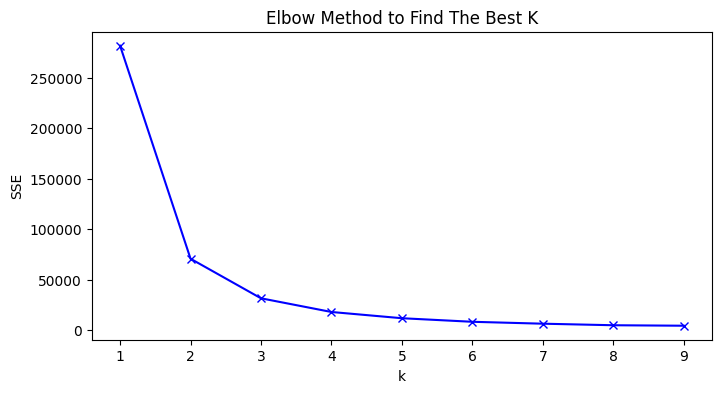

In [16]:
# Find the best k
# using Elbow Method

# List SSE values
sse = []

# Build k range from 1 to 9
K = range(1,10)

# Find the SSE value for each k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

Berdasarkan hasil lineplot SSE untuk setiap $k$, maka kita dapat berargumen bahwa nilai $k$ terbaik adalah 3. Mengapa $k=3$? Hal ini dikarenakan pada nilai $k=2$ nilai SSE masih terlalu tinggi dibandingkan dengan $k=4$, sedangkan, misal $k=8$ sangat rendah. **Jumlah cluster terbaik bukan karena nilai SSE yang rendah**. SSE pasti akan semakin mengecil seiring dengan jumlah cluster yang dihasilkan. Hal ini dikarenakan jumlah anggota tiap *cluster* juga semakin mengecil dan *cluster* otomatis lebih sempit. **Dalam konteks ini, kita harus dapat menemukan posisi dimana nilai** $k$ **telah turun dengan tajam diikuti dengan penurunan yang lebih stabil**. Posisi inilah yang dikenal dengan posisi "elbow". Dalam konteks fitur yang kita gunakan saat ini, nilai $k=3$ menjadi nilai yang paling optimal.